# GRB Flux vs Time Plot
This notebook plots the Flux vs Time (in days) for three GRBs: GRB130427A, GRB130606A, and GRB221009A.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
def read_qdp(filename):
    """
    Reads a QDP file and returns time, time_err_pos, time_err_neg, flux, flux_err_pos, flux_err_neg.
    """
    data = []
    with open(filename, 'r') as f:
        for line in f:
            line = line.strip()
            # Skip comments and QDP command lines
            if line.startswith('!') or line.startswith('READ') or line.startswith('NO') or not line:
                continue
            
            # Parse the numeric values
            try:
                parts = line.split()
                if len(parts) >= 6:
                    values = [float(p) for p in parts[:6]]
                    data.append(values)
            except ValueError:
                # In case there are some non-numeric values in a line
                continue
                
    data = np.array(data)
    
    # Extract columns
    time_sec = data[:, 0]
    time_err_pos = data[:, 1]
    time_err_neg = np.abs(data[:, 2]) # QDP negative errors are usually written as negative numbers
    flux = data[:, 3]
    flux_err_pos = data[:, 4]
    flux_err_neg = np.abs(data[:, 5])
    
    # Convert time from seconds to days
    time_days = time_sec / 86400.0
    time_err_pos_days = time_err_pos / 86400.0
    time_err_neg_days = time_err_neg / 86400.0
    
    return time_days, time_err_pos_days, time_err_neg_days, flux, flux_err_pos, flux_err_neg

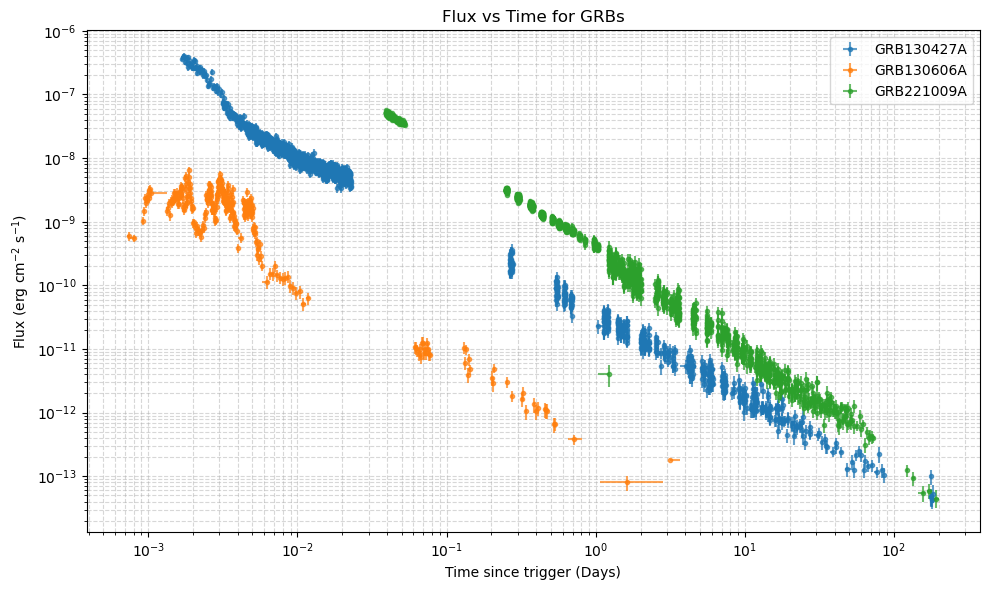

In [3]:
grbs = ["GRB130427A", "GRB130606A", "GRB221009A"]
data_dir = "." # Assumes the script is run in the same directory as the QDP files

plt.figure(figsize=(10, 6))

for grb in grbs:
    filepath = os.path.join(data_dir, f"{grb}.qdp")
    if os.path.exists(filepath):
        t, t_err_pos, t_err_neg, f, f_err_pos, f_err_neg = read_qdp(filepath)
        
        # Plot with asymmetrical error bars
        plt.errorbar(t, f, xerr=[t_err_neg, t_err_pos], yerr=[f_err_neg, f_err_pos], 
                     fmt='o', markersize=3, label=grb, alpha=0.7)
    else:
        print(f"File not found: {filepath}")

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Time since trigger (Days)')
plt.ylabel('Flux (erg cm$^{-2}$ s$^{-1}$)')
plt.title('Flux vs Time for GRBs')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()

# GRB Luminosity vs Time Plot
This cell plots the Isotropic Equivalent Luminosity vs Time for the three GRBs.

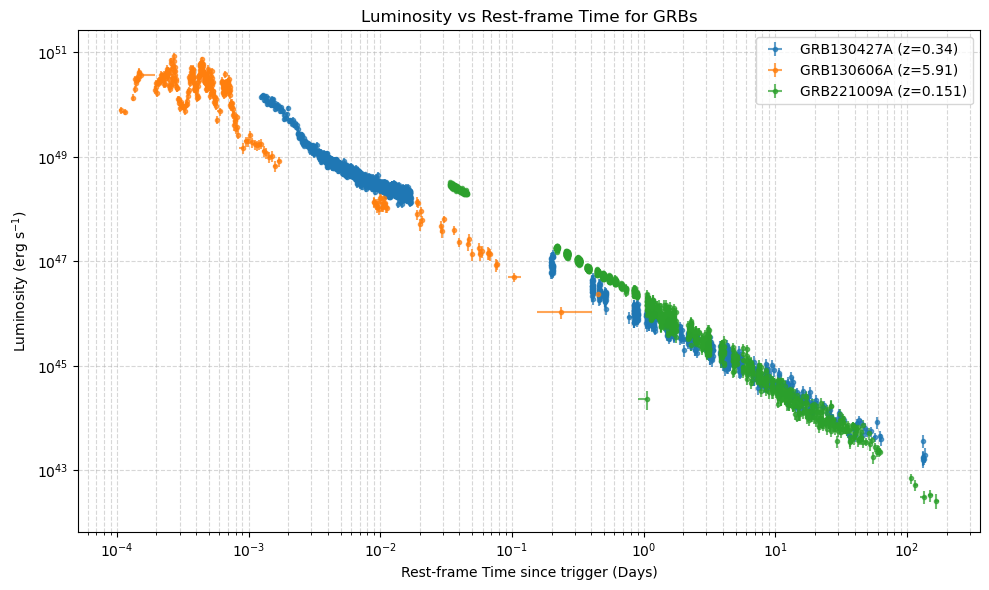

In [4]:
from astropy.cosmology import FlatLambdaCDM
import astropy.units as u

def luminosity_distance(z, H0=70.0, Om0=0.3):
    """Calculate luminosity distance in cm for a flat LambdaCDM cosmology using astropy."""
    cosmo = FlatLambdaCDM(H0=H0, Om0=Om0)
    dl = cosmo.luminosity_distance(z)
    return dl.to(u.cm).value

redshifts = {
    "GRB130427A": 0.34,
    "GRB130606A": 5.91,
    "GRB221009A": 0.151
}

# Spectral indices (beta = Gamma - 1) 
betas = {
    "GRB130427A": 0.901,
    "GRB130606A": 0.44,
    "GRB221009A": 0.503
}

plt.figure(figsize=(10, 6))

for grb in grbs:
    filepath = os.path.join(data_dir, f"{grb}.qdp")
    if os.path.exists(filepath):
        t, t_err_pos, t_err_neg, f, f_err_pos, f_err_neg = read_qdp(filepath)
        
        z = redshifts[grb]
        dl_cm = luminosity_distance(z)
        
        # 1. Rest-frame time correction
        t_rest = t / (1 + z)
        t_err_pos_rest = t_err_pos / (1 + z)
        t_err_neg_rest = t_err_neg / (1 + z)
        
        # 2. K-Correction
        beta = betas[grb]
        k_correction = (1 + z) ** (beta - 1)
        
        # Calculate luminosity L = 4 * pi * dl^2 * F * k_correction
        factor = 4 * np.pi * (dl_cm ** 2) * k_correction
        L = f * factor
        L_err_pos = f_err_pos * factor
        L_err_neg = f_err_neg * factor
        
        plt.errorbar(t_rest, L, xerr=[t_err_neg_rest, t_err_pos_rest], yerr=[L_err_neg, L_err_pos], 
                     fmt='o', markersize=3, label=f"{grb} (z={z})", alpha=0.7)

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Rest-frame Time since trigger (Days)')
plt.ylabel('Luminosity (erg s$^{-1}$)')
plt.title('Luminosity vs Rest-frame Time for GRBs')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()